<img src="./logo_UTN.svg" align="right" width="150" />

# Tarea Semanal 10

*Alumno: Lapilli Cañedo, Mariano Adrian*

In [1]:
# Importo librerias de python para trabajar

import numpy as np
from scipy import signal as sig
import sympy as sp
import control as ct
from matplotlib import pyplot as plt
from pytc2.remociones import remover_polo_dc
from pytc2.general import a_equal_b_latex_s, print_latex, s, symbfunc2tf, factorSOS
from pytc2.sistemas_lineales import bodePlot, pzmap, GroupDelay, analyze_sys
from pytc2.sistemas_lineales import pretty_print_lti
from pytc2.general import print_latex, a_equal_b_latex_s
from pytc2.cuadripolos import calc_MAI_ztransf_ij_mn
from pytc2.cuadripolos import calc_MAI_vtransf_ij_mn
import sympy as sp
import control.matlab as ctl
from pytc2.sintesis_dipolo import foster
from pytc2.dibujar import dibujar_foster_serie
from pytc2.dibujar import dibujar_foster_derivacion
from pytc2.sintesis_dipolo import cauer_LC
from pytc2.dibujar import dibujar_cauer_LC

## Consigna

**Parte A:**  Diseñe el cuadripolo A para que se comporte como:

- Filtro pasa bajos Chevy de 3er. orden 

- No disipativo

- Normalizado en frecuencia e impedancia

Respetando la siguiente topología:

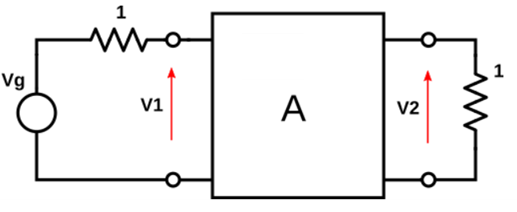

Obtenga la impedancia de entrada al cuadripolo **A**, cargado con un resistor de 1Ω a la salida.
Sintetice **A** como un cuadripolo escalera.
Simule el comportamiento de la red en LTspice graficando $S_{21}$ y $S_{11}$ en función de la frecuencia. (Ver explicación de Agustín Alba Chicar 1h 48m).

Explique el comportamiento de A a partir de los valores de $S_{11}$ en las siguientes frecuencias:
- Centro de la banda de paso
- Frecuencia de corte
- Transición y centro de la banda de detenida

Modifique el circuito para que la frecuencia de corte sea 2π 10⁶ rad/s y la resistencia del generador sea 50Ω.

**Parte B:** Trabajo de Investigación sobre NANO VNA ( Vector Network Analyzer )

1. Explique brevemente la función principal de un VNA y en que situación/es puede ser fundamental tenerlo como herramienta de medición.
   
2. Comparar respecto a un DSO GW Insteak características de: Ancho de Banda, Rango Dinámico e Impedancia de Entrada.
 
3. Además de las mediciones de los parametros  , investigar si el equipo cuenta con alguna medición en el dominio del tiempo.

## Resolución

### Parte A

Resolución


array([-0.14901791+0.90366975j, -0.14901791-0.90366975j,
        0.14901791+0.90366975j,  0.14901791-0.90366975j,
       -0.29803582+0.j        ,  0.29803582+0.j        ])

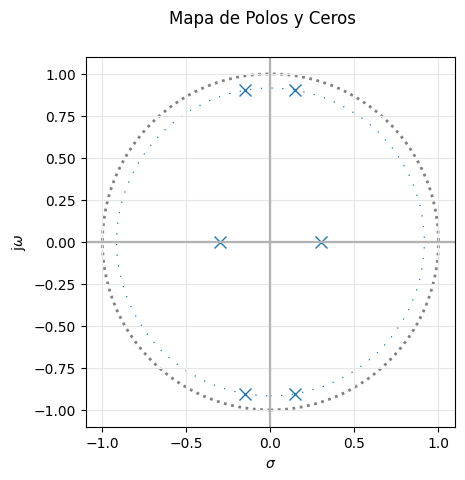

In [6]:
# Busco los polos del módulo de la transferencia.

num = [0, 1]

den = [-16, 0, -24, 0, -9, 0, 1]

H = sig.TransferFunction(num, den)

pzmap(H)

plt.show

np.roots(den)

Simulación en Spice

<img src="./ParteA1.png" width="1000" />
<img src="./ParteA2.png" width="1000" />

Analizando el parámetro **S11**:

- En la Banda de paso y en frecuencias bajas, las bobinas son cortocircuitos y los capacitores son circuitos abiertos por lo que la adapatción es perfecta. **S12** esta plantada en 0 dB y la transferencia de potencia es máxima.
- En la frecuencia de corte, vemos que los parámetros **S11** **S12** se dividen (uno para arriba y otro para abajo) en partes iguales. Lo que indica que parte se refleja y parte se transmite.
- En frecuencias altas **S11** va a 0 dB y **S12** empieza a caer. Es un índice de que la transferencia de potencia cae debido a que la red se desadapta.

Con el circuito modificado:

<img src="./ParteA3.png" width="1000" />

<img src="./ParteA4.png" width="1000" />

### Parte B

a. La función de un VNA es la de analizar redes de alta frecuencia midiendo magnitud y fase de la onda incidente, reflejada y transmitida, a partir de la obtención de los parámetros S de la red. 

Es útil en las siguientes aplicaciones:

- Medición de antenas.
  
- Diseño y verificación de filtros de RF.
  
- Adaptación de impedancias en líneas de transmisión.

b. Comparativa en:

- Ancho de Banda: El Osciloscopio cuenta con anchos de banda en el orden de los MHz mientras que el VNA tiene anchos de banda en el orden de los GHz.

- Rango Dinámico: 50dB a 70dB en el caso del VNA y 40dB a 48dB para el Osciloscopio

- Impedancia de Entrada: 50$\Omega$ para el VNA y entradas de alta impedancia (del orden de los M$\Omega$) para el Osciloscopio.

c. Si se puede mediante la función TDR (reflectometría en el dominio del tiempo). El equipo hace un barrido en frecuencia y calcula la Transformada Rápida de Fourier Inversa (IFFT) por software.
